# HW4 — Full-data development: A and D

**Purpose:** compare the fixed A and D models on the larger stock universe. Use only observations through December 31, 2015. The before-fix results are archived in `before_fix/`. This execution writes only to `after_fix/`. This is development, not the final test.

```text
Bounded source reads (2000–2015)
          ↓
Stock groups → Existing features and targets → Disk cache
                                                ↓
                            Whole-date financial sector ranks (D)
                                                ↓
                      Annual training (2013, 2014, 2015)
                                                ↓
                   Monthly ranking → Orders → Lots → Daily NAV
                                                ↓
                         Reconciliations → Tables and four charts
```

**Run instructions**
1. Select the course `.venv` Python kernel.
2. Check the paths and dates in the settings cell.
3. Select **Restart Kernel and Run All Cells**.
4. Read each table before the next section.

The source database must already be cleaned. Do not rerun notebook 04. This notebook does not write to its outputs. All new results go to `outputs/full_data_development/`, with separate run folders. Functions live in `feature_engineering.py` and `strategy_backtest.py`.

Memory: build features in groups of 50 full stock histories. Save eligible rows from 2010 to a development-only cache. Rank each whole date across all eligible stocks, never within a stock group. This changes storage, not formulas or samples.

> **Development step, full data, 2010-2015 only.** Models A and D before and after the target clip and volatility screen. Later rounds (`run_suspect_rule.py`, `run_portfolio_round.py`) fixed the remaining settings. The final strategy is defined in `run_final_test.py` and reported in `07_final_test_report.ipynb`.

## Two fixed rules for this rerun

1. At each annual fit, learn the 1st and 99th target percentiles from that fit's completed training rows. Clip a copy of the training target. Keep raw targets for IC, R², RMSE, decile outcomes, and the backtest.
2. At each signal date, compute the 80th percentile of raw 63-session volatility across eligible stocks. Exclude values above that threshold from new purchases. Keep values equal to the threshold. Do not screen training rows or held positions.

Both runs use the same rules. Keep features, alpha, allocation, top ten, budget, caps, fees, refit dates, and no-quote policy unchanged. No stock is excluded by name. No database price is changed.

The main yearly score comparison uses all eligible forecasts before and after. This keeps the scoring universe comparable. The decile analysis also shows the screened candidate universe. A forecast remains available for analysis even if the stock fails the purchase screen.

In [1]:
from pathlib import Path
from dataclasses import asdict
from time import perf_counter
import sys, gc, hashlib, json, io, unittest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Lectures/modeling').is_dir())
HW_DIR = ROOT / 'Homeworks/HW4/Mauricio_Gutierrez'
sys.path.insert(0, str(HW_DIR))
from feature_engineering import (PRICE_FEATURES, D_RATIOS, build_full_development_cache,
    load_development_inputs, fit_cached_development, development_coverage,
    no_quote_diagnostics, rank_ic_stability, cached_trade_errors, process_peak_memory_mib,
    forecast_decile_report, forecast_range_report)
from strategy_backtest import (BacktestConfig, Backtester, InverseVolatilityStrategy,
    detailed_performance, reconcile_account, portfolio_chart_data)

# Change paths here. Keep the development date boundary fixed.
DB_PATH = HW_DIR / 'outputs/data_cleaning/equities_top2000/equities_top2000_cleaned.duckdb'
START = '2013-01-02'
END = '2015-12-31'
LOOKBACK_START = '2000-01-01'
TRAIN_START = '2010-01-01'
EXPERIMENT_NAME = {'A':'run_a_allocation_only', 'D':'run_d_price_financial'}
OUTPUT_BASE = HW_DIR / 'outputs/full_data_development'
BEFORE_ROOT = OUTPUT_BASE / 'before_fix'
OUTPUT_ROOT = OUTPUT_BASE / 'after_fix'
CACHE_PATH = OUTPUT_BASE / 'development_features.duckdb'
TARGET_CLIP = True
VOLATILITY_QUANTILE = .80
VALIDATION_YEARS = (2013,2014,2015)
ALPHA = 100.0
CONFIG = BacktestConfig(initial_cash=1_000_000, top_n=10, budget_fraction=1/3,
    holding_days=90, stock_limit=.30, sector_limit=.50, fee_rate=.001, risk_free_rate=.02)
FEATURES = {'A': PRICE_FEATURES, 'D': PRICE_FEATURES + D_RATIOS + ['filing_age_days']}
assert pd.Timestamp(START) <= pd.Timestamp(END) <= pd.Timestamp('2015-12-31')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
run_started = perf_counter()
db_stat_before = (DB_PATH.stat().st_size, DB_PATH.stat().st_mtime_ns)
protected_paths = [HW_DIR / '04_feature_and_allocation_tests.ipynb']
protected_paths += [p for p in (HW_DIR/'outputs/feature_and_allocation_tests').rglob('*') if p.is_file()]
protected_paths += [p for p in BEFORE_ROOT.rglob('*') if p.is_file()]
protected = {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in protected_paths}
# Never hash the full database: its bytes contain post-development observations.
display(pd.Series(asdict(CONFIG),name='Fixed settings').to_frame())
print('Only A and D will run. Real observations stop at', END)

Only A and D will run. Real observations stop at 2015-12-31


,Fixed settings
initial_cash,1000000.000000
top_n,10.000000
budget_fraction,0.333333
holding_days,90.000000
stock_limit,0.300000
sector_limit,0.500000
fee_rate,0.001000
risk_free_rate,0.020000


## 1. Check the execution rule

Use adjusted closes, as in notebook 04. Never fill the source price table.

1. Use the last observed adjusted close when a held stock has no quote.
2. Record the affected lot, session, price date, and marked value.
3. Sell at the first observed close on or after the 90-calendar-day maturity.
4. Count ten market sessions strictly after maturity.
5. If no quote arrives by the tenth session, sell at the last observed close and flag the exit.
6. If a quote arrives on the tenth session, use that quote.
7. Cancel an entry order with no entry-close quote.

At the development cutoff, retain an open lot if its timeout has not arrived. Do not inspect later quotes. The old strict mode remains the default for earlier notebooks.

**Target:** keep the original 90-day target and zero exit delay. An unavailable target stays missing. Only targets completed before the annual fit enter training. This target rule is separate from the new portfolio execution rule.

In [2]:
suite = unittest.defaultTestLoader.discover(str(HW_DIR), pattern='test_*.py')
test_log = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_log,verbosity=1).run(suite)
print(test_log.getvalue())
assert test_result.wasSuccessful()
(OUTPUT_ROOT/'tests.txt').write_text(test_log.getvalue(),encoding='utf-8')

..................................................
----------------------------------------------------------------------
Ran 50 tests in 2.617s

OK

Out[0]: 149


## 2. Build the bounded feature cache

A uses momentum over 21 and 63 sessions, momentum from session −252 to −21, annualized 63-session volatility, and drawdown from the 252-session high.

D adds net income/revenue, operating income/assets, debt/assets, cash/assets, and filing age in days. Rank the four ratios within sector on each date. Use the whole eligible cross-section if a sector has fewer than five eligible stocks. Leave filing age and price features unranked. Keep missing values for training-only median imputation.

Financial reports enter only from their available date. The course helpers also exclude stale ratios. Sector labels are source-snapshot metadata; this source does not provide historical sector classifications. Vendor restatements remain a limitation.

Use membership for the next-session entry quarter. Preserve all stock history for features and held-position quotes.

In [3]:
cache_audit = build_full_development_cache(DB_PATH,CACHE_PATH,
    lookback_start=LOOKBACK_START,train_start=TRAIN_START,end=END,group_size=50)
display(pd.Series(cache_audit,name='Cache audit').to_frame())
pd.DataFrame([cache_audit]).to_csv(OUTPUT_ROOT/'cache_audit.csv',index=False)
gc.collect()
# The execution engine needs only evaluation-period quotes.
prices, calendar, membership, sectors, benchmark, input_audit = load_development_inputs(
    DB_PATH,end=END,lookback_start=START)
assert prices.date.max() <= pd.Timestamp(END)
assert benchmark.date.max() <= pd.Timestamp(END)
display(input_audit.to_frame())

,Cache audit
price_rows_read,7.743241e+06
stocks_with_pre_cutoff_prices,2.676000e+03
eligible_model_rows,2.967026e+06
seconds,8.567016e+01
peak_process_memory_mib,9.282578e+02


,Input audit
price_rows_read,1855879
exact_duplicates_removed,0
invalid_price_rows_excluded,0
price_rows_used,1855879


## 3. Fit and run the fixed experiments

Fit once at the first eligible signal in each of 2013, 2014, and 2015. Use all completed eligible training targets from 2010 onward. Fit clipping, median imputation, missing indicators, scaling, and Ridge on training rows only. Keep alpha at 100.

Use the top ten feasible forecasts. Allocate by inverse raw 63-session volatility. Use `min(cash, NAV/3)`. Include open lots when applying the 30% stock cap and 50% sector cap. Charge 0.10% on each side.

The zero-recovery stress case uses the same fitted forecasts. It assigns zero proceeds and zero sale fee to a no-quote exit. It recomputes later allocations from the changed cash and NAV. This is a sensitivity check, not another fitted model. Also save a fixed-ledger deduction for reference.

In [4]:
accounts, forecasts_by_run = {}, {}
score_parts, split_parts, coefficient_parts, performance_parts = [], [], [], []
coverage_parts, eligibility_parts, fallback_parts, no_quote_parts, runtime_parts = [], [], [], [], []
closed_tables, nav_curves, reconciliation_rows = {}, pd.DataFrame(), []
for name in ['A','D']:
    started = perf_counter()
    run_dir = OUTPUT_ROOT / EXPERIMENT_NAME[name]
    run_dir.mkdir(parents=True, exist_ok=True)
    forecast, scores_run, splits_run, coefficients_run = fit_cached_development(
        CACHE_PATH,name,FEATURES[name],years=VALIDATION_YEARS,train_start=TRAIN_START,alpha=ALPHA,clip_target=TARGET_CLIP)
    account = Backtester(CONFIG,InverseVolatilityStrategy(CONFIG),allow_stale_quotes=True,volatility_quantile=VOLATILITY_QUANTILE).run(
        prices,calendar,forecast,sectors,membership,START,END)
    reconciliation_rows.append({'run':name,'case':'last_close',**reconcile_account(account,calendar,CONFIG)})
    stress = Backtester(CONFIG,InverseVolatilityStrategy(CONFIG),allow_stale_quotes=True,no_quote_recovery=0,volatility_quantile=VOLATILITY_QUANTILE).run(
        prices,calendar,forecast,sectors,membership,START,END)
    reconciliation_rows.append({'run':name,'case':'zero_recovery',**reconcile_account(stress,calendar,CONFIG)})
    diagnostics = no_quote_diagnostics(account,stress).rename(name)
    no_quote_parts.append(diagnostics)
    stress.daily.to_csv(run_dir/'zero_recovery_daily.csv',index=False)
    stress.trades.to_csv(run_dir/'zero_recovery_trades.csv',index=False)
    del stress
    curves, perf = detailed_performance(account,benchmark,CONFIG)
    nav_curves[name] = curves.Strategy
    performance_parts.append(perf.loc[['Strategy']].rename(index={'Strategy':name}))
    closed = cached_trade_errors(CACHE_PATH,account,forecast,benchmark)
    closed_tables[name] = closed
    closed.to_csv(run_dir/'closed_trade_errors.csv',index=False)
    closed.head(20).to_csv(run_dir/'largest_20_misses.csv',index=False)
    forecast.to_csv(run_dir/'forecasts.csv',index=False)
    scores_run.to_csv(run_dir/'model_scores.csv',index=False)
    splits_run.to_csv(run_dir/'training_splits.csv',index=False)
    coefficients_run.to_csv(run_dir/'ridge_coefficients.csv',index=False)
    diagnostics.to_csv(run_dir/'no_quote_diagnostics.csv')
    for scope, first in [('training_and_evaluation',TRAIN_START),('evaluation',START)]:
        missing, eligible, eligible_summary, fallback = development_coverage(CACHE_PATH,name,FEATURES[name],start=first,end=END)
        missing.assign(run=name,scope=scope).to_csv(run_dir/f'{scope}_missing_features.csv',index=False)
        eligible.to_csv(run_dir/f'{scope}_eligible_stocks_by_date.csv',index=False)
        eligible_summary.to_csv(run_dir/f'{scope}_eligible_stock_summary.csv')
        coverage_parts.append(missing.assign(run=name,scope=scope))
        eligibility_parts.append(eligible_summary.T.assign(run=name,scope=scope))
        if name=='D':
            fallback.assign(scope=scope).to_csv(run_dir/f'{scope}_financial_rank_fallback.csv',index=False)
            fallback_parts.append(fallback.assign(scope=scope))
    for field in ['daily','trades','orders','decisions','rejections','open_lots','valuation_flags']:
        getattr(account,field).to_csv(run_dir/f'{field}.csv',index=False)
    accounts[name], forecasts_by_run[name] = account, forecast
    score_parts.append(scores_run); split_parts.append(splits_run); coefficient_parts.append(coefficients_run)
    runtime = {'run':name,'seconds':perf_counter()-started,'peak_process_memory_mib':process_peak_memory_mib()}
    runtime_parts.append(runtime)
    pd.DataFrame([runtime]).to_csv(run_dir/'runtime.csv',index=False)
    manifest = {'experiment_name':EXPERIMENT_NAME[name],'start':START,'end':END,'lookback_start':LOOKBACK_START,
        'train_start':TRAIN_START,'annual_refits':VALIDATION_YEARS,'alpha':ALPHA,'features':FEATURES[name],
        'target':'90-calendar-day stock return; original zero-delay label', 'config':asdict(CONFIG),
        'training_target_clip_quantiles':[.01,.99], 'candidate_volatility_quantile':VOLATILITY_QUANTILE,
        'no_quote_rule':'last observed mark; first quoted maturity exit; timeout at tenth session strictly after maturity',
        'zero_recovery_case':'rerun execution with same forecasts and zero timeout proceeds',
        'feature_module_sha256':hashlib.sha256((HW_DIR/'feature_engineering.py').read_bytes()).hexdigest(),
        'backtester_sha256':hashlib.sha256((HW_DIR/'strategy_backtest.py').read_bytes()).hexdigest()}
    (run_dir/'experiment.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    print(f'Run {name} completed in {runtime["seconds"]:.1f} seconds.')
    gc.collect()
nav_curves['S&P 500 TR'] = curves['S&P 500 TR']
performance_parts.append(perf.loc[['S&P 500 TR']])
comparison = pd.concat(performance_parts)
scores = pd.concat(score_parts,ignore_index=True)
splits = pd.concat(split_parts,ignore_index=True)
coefficients = pd.concat(coefficient_parts,ignore_index=True)
coverage = pd.concat(coverage_parts,ignore_index=True)
eligible_summary = pd.concat(eligibility_parts,ignore_index=True)
fallback_summary = pd.concat(fallback_parts,ignore_index=True)
no_quote_summary = pd.DataFrame(no_quote_parts)
reconciliations = pd.DataFrame(reconciliation_rows)
display(reconciliations)

Run A completed in 21.4 seconds.
Run D completed in 31.5 seconds.


,run,case,cash_and_nav,fees_and_lots,maturities,budget
0,A,last_close,PASS,PASS,PASS,PASS
1,A,zero_recovery,PASS,PASS,PASS,PASS
2,D,last_close,PASS,PASS,PASS,PASS
3,D,zero_recovery,PASS,PASS,PASS,PASS


## 4. Compare performance and forecast quality

Use the same dates for A, D, and the benchmark. Sharpe uses a 2% annual risk-free rate. Annualized volatility uses 252 sessions. Include open positions at the cutoff. Fees apply to strategy trades; the total-return index benchmark has no trading fees.

Rank IC measures each date's cross-sectional forecast ranking. RMSE measures error in the original stock-return target. Score only completed targets. A missing target never blocks a forecast.

In [5]:
metric_columns = ['final_value','total_return','CAGR','max_drawdown','annualized_volatility','daily_Sharpe','average_cash_weight','fees_paid']
comparison = comparison[metric_columns]
display(comparison.round(4))
display(scores[['model','year','mean_daily_rank_IC','RMSE','IC_dates','scored_rows','forecast_rows']].round(5))
display(splits)
coefficient_table = coefficients.pivot(index='term',columns=['model','year'],values='coefficient')
display(coefficient_table.round(6))

,final_value,total_return,CAGR,max_drawdown,annualized_volatility,daily_Sharpe,average_cash_weight,fees_paid
portfolio,,,,,,,,
A,1.173016e+06,0.1730,0.0548,-0.2740,0.1789,0.2760,0.1819,26459.7577
D,1.187861e+06,0.1879,0.0592,-0.1800,0.1346,0.3471,0.1814,24062.0992
S&P 500 TR,1.487843e+06,0.4878,0.1420,-0.1204,0.1273,0.9502,0.0000,0.0000


,model,year,mean_daily_rank_IC,RMSE,IC_dates,scored_rows,forecast_rows
0,A,2013,-0.01497,0.33851,252.0,500313,500394
1,A,2014,-0.02075,0.17215,252.0,501331,501414
2,A,2015,-0.07121,0.19137,189.0,376544,500115
3,D,2013,-0.01197,0.33959,252.0,500313,500394
4,D,2014,0.05196,0.17210,252.0,501331,501414
5,D,2015,-0.02565,0.19127,189.0,376544,500115


,model,year,training_rows,first_signal,last_training_outcome,seconds,target_clip_lower,target_clip_upper,target_rows_clipped_low,target_rows_clipped_high,target_rows_clipped
0,A,2013,1343948,2013-01-02,2012-12-31,2.294200,-0.461538,0.716981,13420,13439,26859
1,A,2014,1839721,2014-01-02,2013-12-31,3.112607,-0.440339,0.720190,18398,18398,36796
2,A,2015,2341008,2015-01-02,2014-12-31,4.296998,-0.432673,0.686920,23411,23411,46822
3,D,2013,1343948,2013-01-02,2012-12-31,4.546151,-0.461538,0.716981,13420,13439,26859
4,D,2014,1839721,2014-01-02,2013-12-31,6.368100,-0.440339,0.720190,18398,18398,36796
5,D,2015,2341008,2015-01-02,2014-12-31,8.912786,-0.432673,0.686920,23411,23411,46822


model                                             A  ...         D
year                                           2013  ...      2015
term                                                 ...          
intercept                                  0.032400  ...  0.042169
numeric__cash_to_assets                         NaN  ... -0.003195
numeric__debt_to_assets                         NaN  ...  0.003724
numeric__drawdown_252                     -0.002512  ... -0.003150
numeric__filing_age_days                        NaN  ...  0.002085
numeric__missingindicator_cash_to_assets        NaN  ... -0.000165
numeric__missingindicator_debt_to_assets        NaN  ... -0.001284
numeric__missingindicator_drawdown_252    -0.002457  ... -0.001177
numeric__missingindicator_momentum_252_21 -0.001254  ...  0.000046
numeric__missingindicator_net_margin            NaN  ... -0.005376
numeric__missingindicator_operating_roa         NaN  ... -0.000165
numeric__momentum_21                       0.004815  ...  0.000094
numeric__momentum_252_21                  -0.004708  ... -0.003409
numeric__momentum_63                      -0.012174  ... -0.005008
numeric__net_margin                             NaN  ... -0.001562
numeric__operating_roa                          NaN  ...  0.009087
numeric__volatility_63                     0.004250  ...  0.004891

[17 rows x 6 columns]

## 5. Check missing inputs and eligibility

Show missing shares separately for all eligible rows from 2010 and for evaluation rows. The fitted median uses training data only. Report financial fallback by year.

The eligible-stock count includes zero-count sessions. The last session has no next-session entry inside this bounded calendar, so it has zero eligible forecasts under the original membership function. That boundary is not a missing-price event.

In [6]:
display(coverage)
display(eligible_summary)
display(fallback_summary)

,feature,missing_rows,eligible_rows,missing_share,run,scope
0,momentum_21,0,2967026,0.000000,A,training_and_evaluation
1,momentum_63,0,2967026,0.000000,A,training_and_evaluation
2,momentum_252_21,86175,2967026,0.029044,A,training_and_evaluation
3,volatility_63,0,2967026,0.000000,A,training_and_evaluation
4,drawdown_252,96099,2967026,0.032389,A,training_and_evaluation
5,momentum_21,0,1501923,0.000000,A,evaluation
6,momentum_63,0,1501923,0.000000,A,evaluation
7,momentum_252_21,56196,1501923,0.037416,A,evaluation
8,volatility_63,0,1501923,0.000000,A,evaluation
9,drawdown_252,59370,1501923,0.039529,A,evaluation


,min,median,max,run,scope
0,0.0,1980.0,1999.0,A,training_and_evaluation
1,0.0,1991.0,1999.0,A,evaluation
2,0.0,1980.0,1999.0,D,training_and_evaluation
3,0.0,1991.0,1999.0,D,evaluation


,year,fallback_stock_dates,eligible_stock_dates,fallback_share,scope
0,2010,0.0,476918,0.0,training_and_evaluation
1,2011,0.0,493876,0.0,training_and_evaluation
2,2012,0.0,494309,0.0,training_and_evaluation
3,2013,0.0,500394,0.0,training_and_evaluation
4,2014,0.0,501414,0.0,training_and_evaluation
5,2015,0.0,500115,0.0,training_and_evaluation
6,2013,0.0,500394,0.0,evaluation
7,2014,0.0,501414,0.0,evaluation
8,2015,0.0,500115,0.0,evaluation


## 6. Inspect the four charts

Month-end NAV is the value on the last observed session of each month. Monthly portfolio volatility is the sample standard deviation of daily returns within that month, annualized by √252. It is not the allocation feature.

Drawdown measures the decline from the previous NAV peak. Daily returns show session-to-session changes. Stale marks can delay reported price changes; read the no-quote table with these charts.

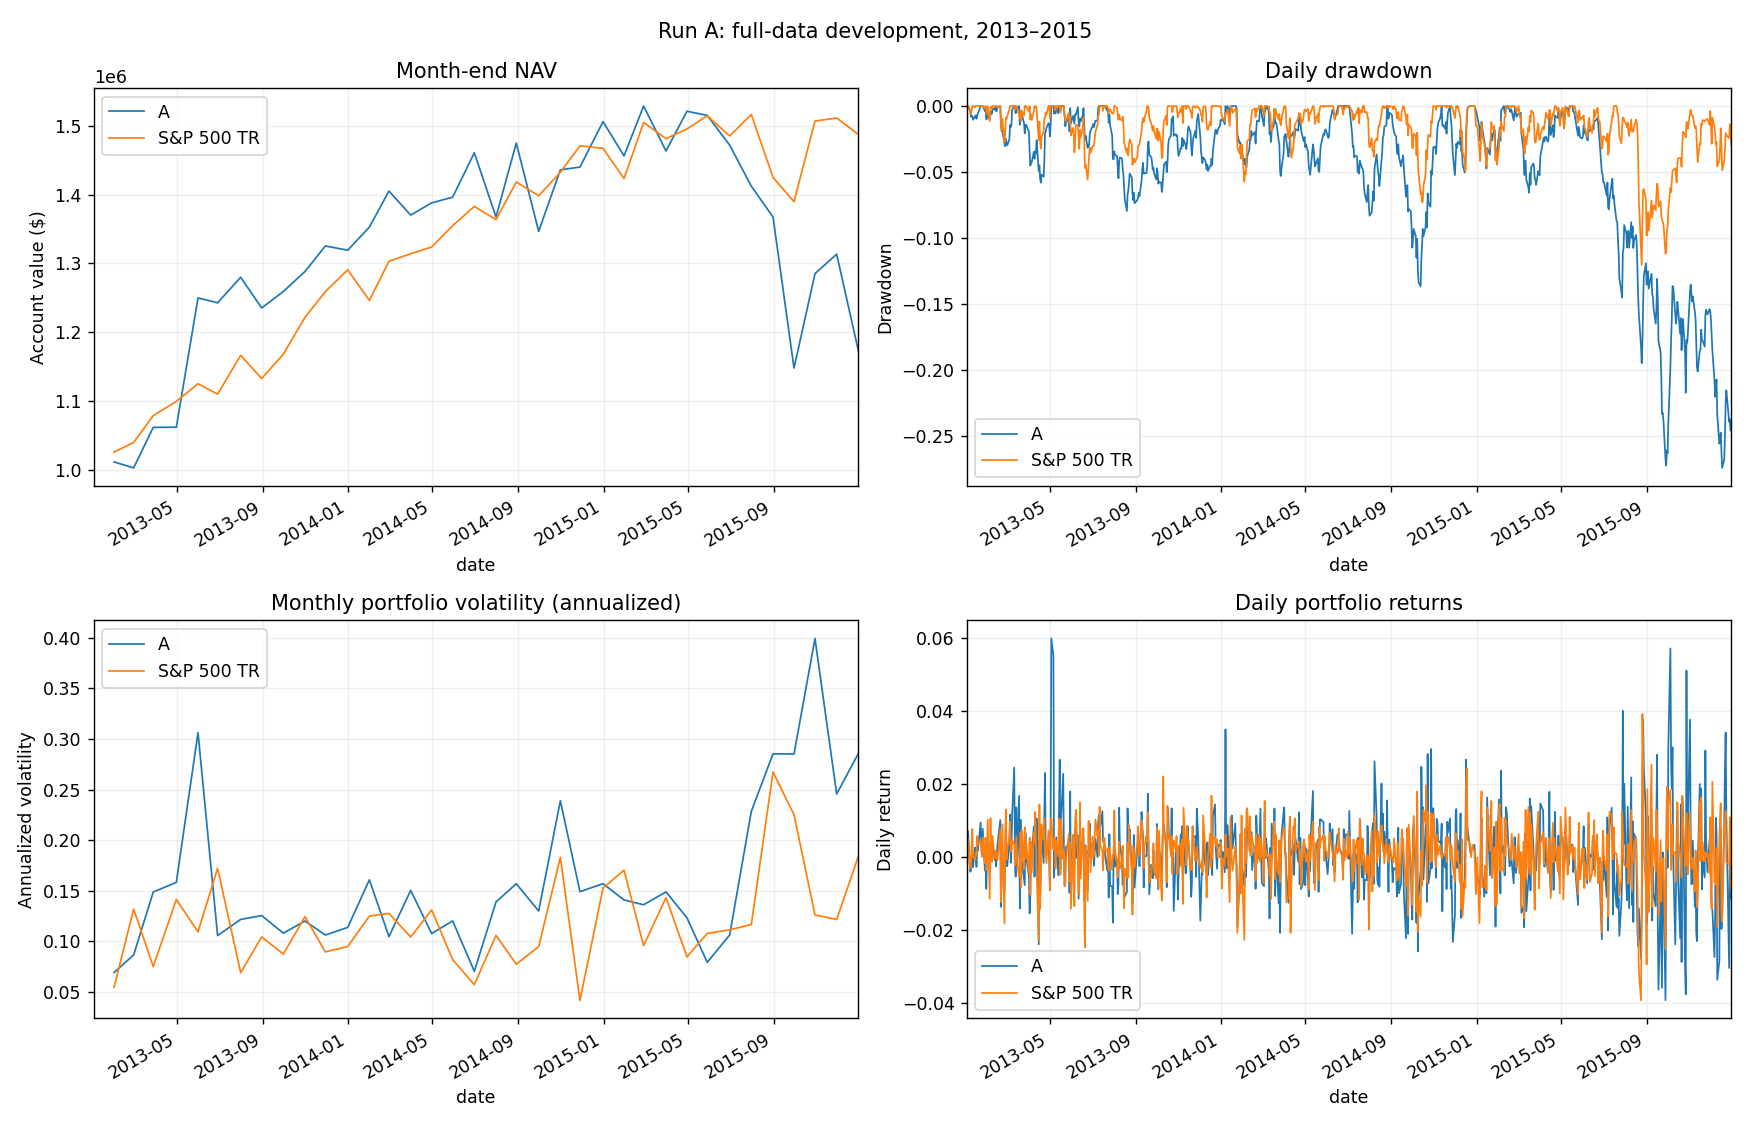

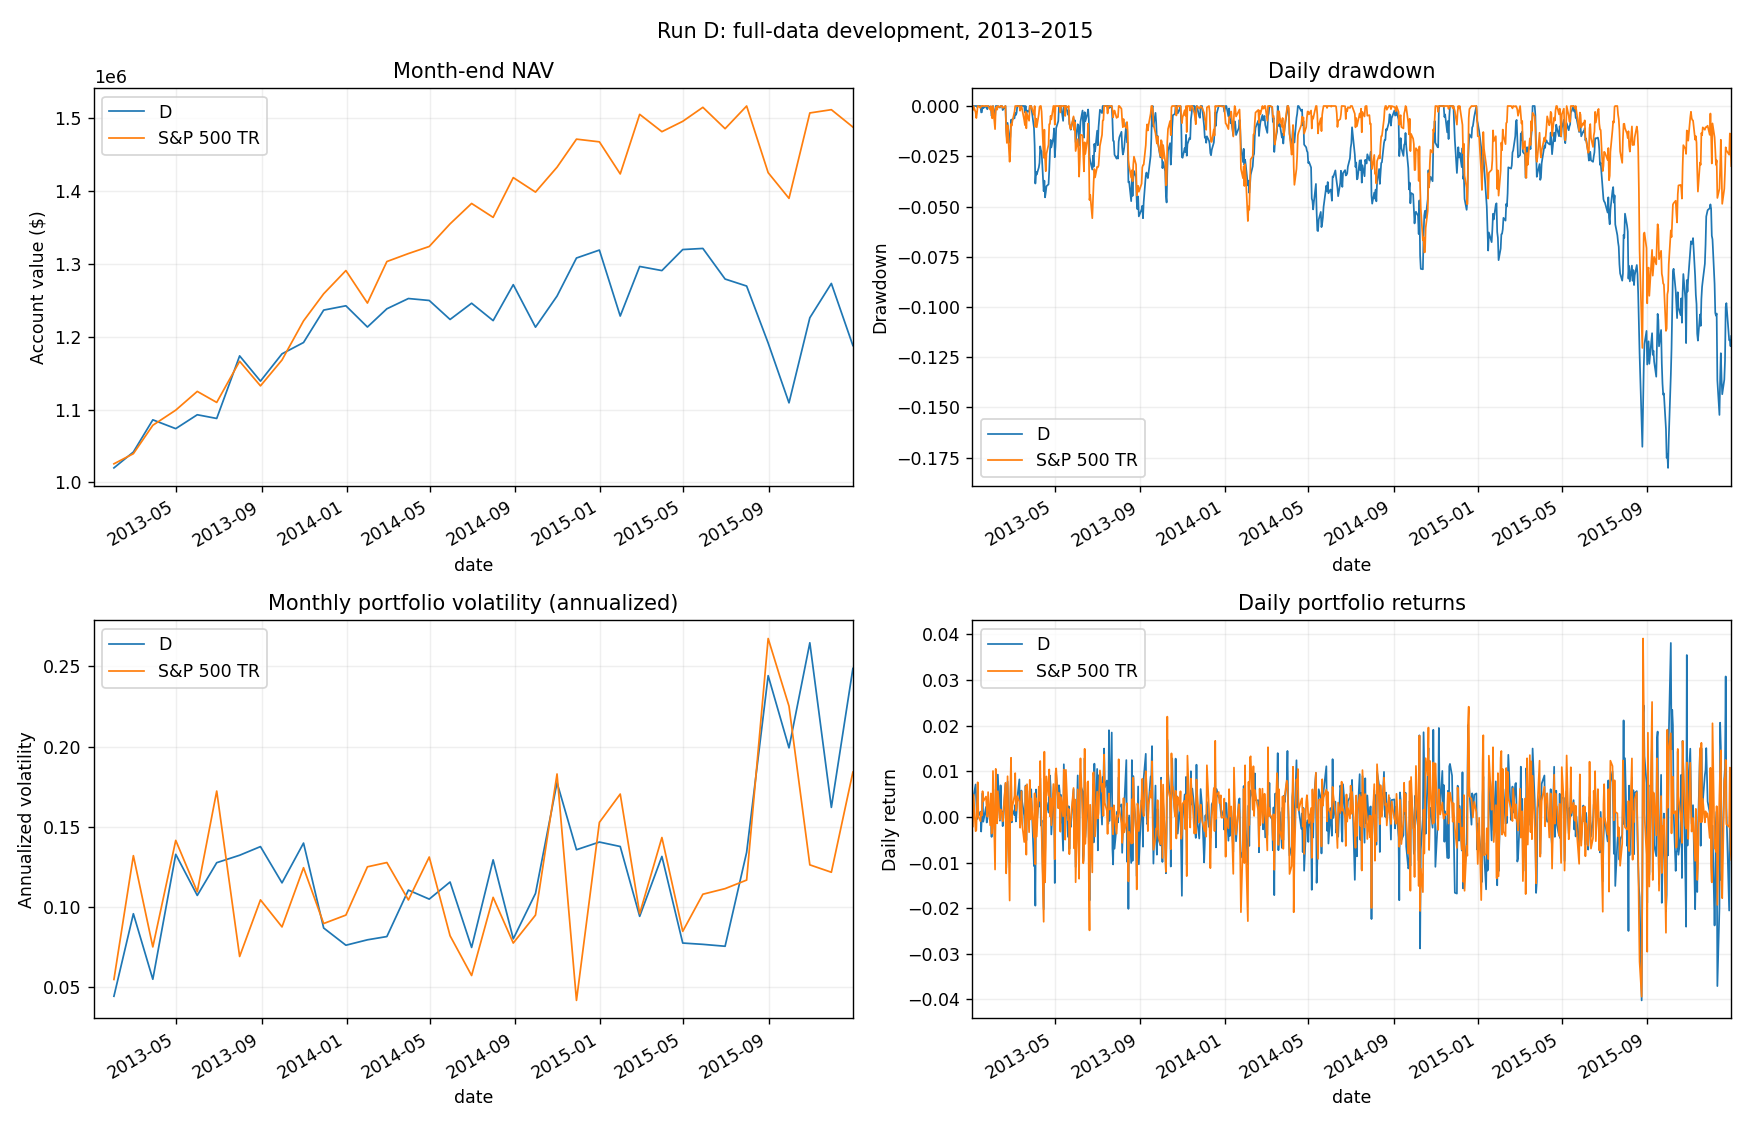

In [7]:
chart_data = portfolio_chart_data(nav_curves)
for name in ['A','D']:
    fig, axes = plt.subplots(2,2,figsize=(14,9))
    fields = [('monthly_nav','Month-end NAV','Account value ($)'),
              ('daily_drawdown','Daily drawdown','Drawdown'),
              ('monthly_volatility','Monthly portfolio volatility (annualized)','Annualized volatility'),
              ('daily_returns','Daily portfolio returns','Daily return')]
    for ax,(field,title,ylabel) in zip(axes.flat,fields):
        chart_data[field][[name,'S&P 500 TR']].plot(ax=ax,linewidth=1,title=title)
        ax.set_ylabel(ylabel); ax.grid(alpha=.2); ax.set_xlim(pd.Timestamp(START),pd.Timestamp(END))
    fig.suptitle(f'Run {name}: full-data development, 2013–2015')
    fig.tight_layout()
    image_buffer = io.BytesIO()
    fig.savefig(image_buffer,format='png',dpi=125)
    (OUTPUT_ROOT/EXPERIMENT_NAME[name]/'strategy_charts.png').write_bytes(image_buffer.getvalue())
    display(Image(data=image_buffer.getvalue()))
    plt.close(fig)

## 7. Inspect forecast misses and no-quote events

Each closed-trade row is one purchased lot. The forecast is the signal-close stock-return forecast. The realized return uses the actual execution dates and gross prices. A delayed or no-quote exit can differ from the original target horizon. Show its flag beside the error.

Entry volatility is retrospective analysis. Allocation used signal-close volatility. Flagged valuation value sums repeated lot-session marks. It is not a loss estimate or unique capital amount. The maximum per-session flagged value avoids summing the same lot across many days.

In [8]:
for name in ['A','D']:
    display(Markdown(f'### Run {name}: 20 largest absolute misses'))
    display(closed_tables[name].head(20)[['symbol','entry_date','exit_date','forecast','realized_return',
        'forecast_minus_realized','volatility_63_at_entry','no_quote_exit']])
display(no_quote_summary)

### Run A: 20 largest absolute misses

,symbol,entry_date,exit_date,forecast,realized_return,forecast_minus_realized,volatility_63_at_entry,no_quote_exit
0,YELL,2013-03-04,2013-06-03,0.046581,2.268534,-2.221952,0.285307,False
1,YELL,2013-02-04,2013-05-06,0.052708,1.535304,-1.482596,0.275890,False
2,INSM,2013-03-04,2013-06-03,0.046509,1.188742,-1.142233,0.319183,False
3,TROX,2015-07-02,2015-09-30,0.057436,-0.688825,0.746261,0.333665,False
4,FSTR,2015-07-02,2015-09-30,0.054209,-0.636914,0.691123,0.234035,False
5,LSCC,2015-10-02,2015-12-31,0.062160,0.734584,-0.672424,0.443787,False
6,GNK,2015-10-02,2015-12-31,0.065414,-0.578066,0.643480,0.415060,False
7,NGVC,2014-11-04,2015-02-02,0.066794,0.707393,-0.640599,0.366233,False
8,TROX,2015-06-02,2015-08-31,0.053590,-0.525559,0.579150,0.322347,False
9,AVID,2013-09-04,2013-12-03,0.050039,0.604693,-0.554654,0.273117,False


### Run D: 20 largest absolute misses

,symbol,entry_date,exit_date,forecast,realized_return,forecast_minus_realized,volatility_63_at_entry,no_quote_exit
0,NGVC,2014-11-04,2015-02-02,0.082738,0.707393,-0.624655,0.366233,False
1,ADES,2014-11-04,2015-02-02,0.079461,-0.525971,0.605431,0.389682,False
2,RM,2014-03-04,2014-06-02,0.076132,-0.496618,0.572750,0.325029,False
3,USNA,2013-02-04,2013-05-06,0.071095,0.581428,-0.510333,0.406406,False
4,JAKK,2014-02-04,2014-05-05,0.082508,0.572695,-0.490187,0.382231,False
5,DXPE,2015-07-02,2015-09-30,0.067858,-0.388204,0.456062,0.326477,False
6,DXPE,2014-09-03,2014-12-02,0.080064,-0.370857,0.450921,0.326993,False
7,AR,2015-07-02,2015-09-30,0.069746,-0.363609,0.433355,0.285279,False
8,DXPE,2014-05-02,2014-07-31,0.073450,-0.351620,0.425070,0.342177,False
9,DXPE,2014-11-04,2015-02-02,0.093958,-0.331032,0.424990,0.325367,False


,flagged_lot_valuations,flagged_stock_sessions,flagged_sessions,flagged_mark_value_sum,maximum_flagged_value_on_one_session,no_quote_exit_count,no_quote_exit_gross_value,no_quote_exit_net_proceeds,zero_recovery_final_value,fixed_ledger_zero_recovery_value
A,1.0,1.0,1.0,56851.053377,56851.053377,0.0,0.0,0.0,1.173016e+06,1.173016e+06
D,20.0,17.0,17.0,591493.554411,75445.315759,0.0,0.0,0.0,1.187861e+06,1.187861e+06


## 8. Compare IC stability and save the audit

Define **steadier IC** as the smaller sample standard deviation of the three yearly mean rank IC values. Report the mean and range too. This definition is fixed before reading results. It does not imply that the steadier model has better ranking or higher returns.

Apart from the two requested fixes, keep settings unchanged. Keep the final-test period closed. Process peak memory is a cumulative operating-system high-water mark, not isolated memory allocated by each model. Runtime excludes Python startup.

In [9]:
stability = rank_ic_stability(scores)
steadier = stability['std'].idxmin()
display(stability)
analysis = (f'Run {steadier} has the steadier yearly rank IC by the fixed sample-standard-deviation rule. '
            f'A: {stability.loc["A","std"]:.5f}; D: {stability.loc["D","std"]:.5f}. '
            f'A Sharpe: {comparison.loc["A","daily_Sharpe"]:.3f}; D Sharpe: {comparison.loc["D","daily_Sharpe"]:.3f}. '
            'Only the two requested rules changed from before fix. No real observations after 2015-12-31 were read.')
print(analysis)
for name, frame in {'performance_comparison':comparison,'model_scores':scores,'training_splits':splits,
    'yearly_ridge_coefficients':coefficients,'yearly_ridge_coefficients_wide':coefficient_table,
    'feature_missingness':coverage,'eligible_stock_summary':eligible_summary,'financial_rank_fallback':fallback_summary,
    'no_quote_summary':no_quote_summary,'reconciliations':reconciliations,'rank_ic_stability':stability,
    **chart_data}.items():
    frame.to_csv(OUTPUT_ROOT/f'{name}.csv')
assert (DB_PATH.stat().st_size,DB_PATH.stat().st_mtime_ns)==db_stat_before
assert all(hashlib.sha256(Path(path).read_bytes()).hexdigest()==value for path,value in protected.items())
runtime = pd.DataFrame(runtime_parts)
runtime.loc[len(runtime)] = ['total_including_cache_and_reports',perf_counter()-run_started,process_peak_memory_mib()]
display(runtime)
runtime.to_csv(OUTPUT_ROOT/'runtime.csv',index=False)
(OUTPUT_ROOT/'analysis.md').write_text(analysis,encoding='utf-8')
(OUTPUT_ROOT/'protected_class_outputs.json').write_text(json.dumps(protected,indent=2),encoding='utf-8')
print('PASS: source metadata unchanged; notebook 04 and its class output checksums unchanged.')

Run A has the steadier yearly rank IC by the fixed sample-standard-deviation rule. A: 0.03093; D: 0.04143. A Sharpe: 0.276; D Sharpe: 0.347. Only the two requested rules changed from before fix. No real observations after 2015-12-31 were read.
PASS: source metadata unchanged; notebook 04 and its class output checksums unchanged.


,mean,std,min,max
model,,,,
A,-0.035645,0.030934,-0.071209,-0.014975
D,0.004780,0.041431,-0.025653,0.051963


,run,seconds,peak_process_memory_mib
0,A,21.445246,1805.824219
1,D,31.524890,3118.480469
2,total_including_cache_and_reports,144.867853,3118.480469


## 9. Read this input-quality limitation

The archived before-fix run had very large forecast errors. A's yearly RMSE ranges from 2.28 to 3.97 in decimal-return units. D's ranges from 3.03 to 5.26. These forecasts are poorly calibrated.

Inspect the existing targets below. This audit does not remove or change a row. The pre-2013 training sample includes an AAM target of 142,707.33. The supplied adjusted price is 0.192 at entry on January 25, 2012 and 27,400 at exit on April 24, 2012. This extreme price change needs source review. It is not evidence of an economically attainable return.

The unchanged cleaner retains large price moves. The before-fix pipeline clipped feature inputs, but did not clip training targets. The corrected fits now clip their training targets at the training-only 1st and 99th percentiles. Extreme training targets can strongly affect Ridge fits. The audit identifies a material source limitation; it does not prove that this one record explains every forecast error. The raw observations remain unchanged. The two requested fixes change the training target passed to Ridge and screen purchase candidates.

Read the before/after tables below to assess the corrected run. This audit continues to show raw targets. Neither scoring outcomes nor execution prices are clipped.

In [10]:
from feature_engineering import largest_completed_training_targets
training_target_audit = largest_completed_training_targets(CACHE_PATH,train_start=TRAIN_START,year=2013)
training_target_audit.to_csv(OUTPUT_ROOT/'largest_pre_2013_training_targets.csv',index=False)
display(training_target_audit)

,symbol,date,label_end,target
0,AAM,2012-01-24,2012-04-24,142707.333333
1,AAM,2012-01-23,2012-04-23,141144.833333
2,AAM,2012-01-20,2012-04-23,139689.721649
3,AAM,2012-01-26,2012-04-26,139312.984169
4,AAM,2012-01-25,2012-04-25,138946.368421
5,AAM,2012-04-27,2012-07-30,106847.563969
6,AAM,2012-04-30,2012-07-30,106847.563969
7,AAM,2011-05-02,2011-08-01,56108.725686
8,AAM,2010-09-02,2010-12-02,55732.944954
9,AAM,2010-09-01,2010-12-01,54856.142857


## 10. Compare before and after

The archived files are read-only references. Compare the same metrics and all three annual fits. The coefficient table includes intercepts. Coefficients apply to standardized inputs and missing indicators; they are not raw-unit effects.

Clipping counts are strict: rows equal to a bound are not counted as changed. The bounds are fitted separately each year and separately for each run. A and D should have the same bounds because they use the same eligible training targets.

In [11]:
# The before-fix archive is this notebook's first run, made with TARGET_CLIP = False and
# VOLATILITY_QUANTILE = None and saved under BEFORE_ROOT. Skip the comparison without it.
if (BEFORE_ROOT/'performance_comparison.csv').is_file():
    before_performance = pd.read_csv(BEFORE_ROOT/'performance_comparison.csv',index_col=0)
    before_scores = pd.read_csv(BEFORE_ROOT/'model_scores.csv')
    before_coefficients = pd.read_csv(BEFORE_ROOT/'yearly_ridge_coefficients.csv')
    performance_before_after = pd.concat({'before_fix':before_performance,'after_fix':comparison},axis=1)
    score_columns = ['mean_daily_rank_IC','R2','RMSE','IC_dates','scored_rows','forecast_rows']
    scores_before_after = pd.concat({
        'before_fix':before_scores.set_index(['model','year'])[score_columns],
        'after_fix':scores.set_index(['model','year'])[score_columns]},axis=1)
    coefficients_before_after = pd.concat({
        'before_fix':before_coefficients.set_index(['model','year','term']).coefficient,
        'after_fix':coefficients.set_index(['model','year','term']).coefficient},axis=1)
    clip_bounds = splits[['model','year','training_rows','last_training_outcome','first_signal',
        'target_clip_lower','target_clip_upper','target_rows_clipped_low','target_rows_clipped_high','target_rows_clipped']]
    display(performance_before_after.round(5))
    display(scores_before_after.round(6))
    display(coefficients_before_after.round(6))
    display(clip_bounds)
    for name,table in {'performance_before_after':performance_before_after,'scores_before_after':scores_before_after,
        'coefficients_before_after':coefficients_before_after,'training_target_clip_bounds':clip_bounds}.items():
        table.to_csv(OUTPUT_BASE/f'{name}.csv')
else:
    print('Before-fix archive not found: skipping the before/after comparison.')

before_fix               ...           after_fix             
             final_value total_return  ... average_cash_weight    fees_paid
portfolio                              ...                                 
A           1.205683e+06      0.20568  ...             0.18188  26459.75770
D           1.376423e+06      0.37642  ...             0.18144  24062.09925
S&P 500 TR  1.487843e+06      0.48784  ...             0.00000      0.00000

[3 rows x 16 columns]

before_fix              ...   after_fix              
           mean_daily_rank_IC          R2  ... scored_rows forecast_rows
model year                                 ...                          
A     2013           0.043599 -140.207679  ...      500313        500394
      2014          -0.079086 -278.894331  ...      501331        501414
      2015          -0.018854 -153.130237  ...      376544        500115
D     2013           0.037215 -247.893349  ...      500313        500394
      2014           0.001991 -504.773953  ...      501331        501414
      2015          -0.023429 -270.699663  ...      376544        500115

[6 rows x 12 columns]

before_fix  after_fix
model year term                                                           
A     2013 numeric__momentum_21                       -2.110627   0.004815
           numeric__momentum_63                       -1.617996  -0.012174
           numeric__momentum_252_21                   -0.705787  -0.004708
           numeric__volatility_63                      6.006109   0.004250
           numeric__drawdown_252                       3.602511  -0.002512
...                                                         ...        ...
D     2015 numeric__missingindicator_net_margin       -0.123872  -0.005376
           numeric__missingindicator_operating_roa     0.002643  -0.000165
           numeric__missingindicator_debt_to_assets   -0.093241  -0.001284
           numeric__missingindicator_cash_to_assets    0.002643  -0.000165
           intercept                                   0.589284   0.042169

[75 rows x 2 columns]

,model,year,training_rows,last_training_outcome,first_signal,target_clip_lower,target_clip_upper,target_rows_clipped_low,target_rows_clipped_high,target_rows_clipped
0,A,2013,1343948,2012-12-31,2013-01-02,-0.461538,0.716981,13420,13439,26859
1,A,2014,1839721,2013-12-31,2014-01-02,-0.440339,0.720190,18398,18398,36796
2,A,2015,2341008,2014-12-31,2015-01-02,-0.432673,0.686920,23411,23411,46822
3,D,2013,1343948,2012-12-31,2013-01-02,-0.461538,0.716981,13420,13439,26859
4,D,2014,1839721,2013-12-31,2014-01-02,-0.440339,0.720190,18398,18398,36796
5,D,2015,2341008,2014-12-31,2015-01-02,-0.432673,0.686920,23411,23411,46822


## 11. Inspect forecast scale and daily deciles

Show the 20 largest forecasts for each run, with signal volatility and the purchase-screen flag. Also save the 20 largest forecasts that pass the screen. These are stock-date predictions, not necessarily executed trades.

Decile 1 contains the lowest forecasts. Decile 10 contains the highest. Form ten near-equal groups separately on each date. Break forecast ties by symbol. Assign deciles before removing rows with unobserved outcomes. Keep realized 90-day returns unclipped.

The main annual decile value is the average of the daily decile means, with equal weight for each scored date. Save the pooled stock-date mean too. The spread is the average same-date decile-10 minus decile-1 return. Daily 90-day horizons overlap; these values are not independent trade returns. No post-2015 outcome is used.

The forecast-range table checks for predictions below −100% or above +100%. Plausible scale does not establish predictive accuracy. Raw outcome anomalies can still affect RMSE, R², and realized decile means.

In [12]:
range_parts, decile_parts, spread_parts = [], [], []
for name in ['A','D']:
    run_dir = OUTPUT_ROOT/EXPERIMENT_NAME[name]
    ranges,largest,largest_candidates = forecast_range_report(forecasts_by_run[name])
    range_parts.append(ranges.assign(model=name))
    display(Markdown(f'### {name}: 20 largest forecasts after the fix'))
    display(largest[['date','symbol','prediction','volatility_63','volatility_threshold','passes_volatility_screen']])
    largest.to_csv(run_dir/'largest_20_forecasts.csv',index=False)
    largest_candidates.to_csv(run_dir/'largest_20_candidate_forecasts.csv',index=False)
    ranges.to_csv(run_dir/'forecast_range.csv',index=False)
    for scope,screened in [('all_eligible',False),('screened_candidates',True)]:
        deciles,spread = forecast_decile_report(forecasts_by_run[name],screened=screened)
        deciles.to_csv(run_dir/f'{scope}_forecast_deciles.csv',index=False)
        spread.to_csv(run_dir/f'{scope}_top_minus_bottom.csv',index=False)
        decile_parts.append(deciles.assign(model=name,scope=scope))
        spread_parts.append(spread.assign(model=name,scope=scope))
forecast_ranges = pd.concat(range_parts,ignore_index=True)
decile_returns = pd.concat(decile_parts,ignore_index=True)
decile_spreads = pd.concat(spread_parts,ignore_index=True)
decile_table = decile_returns.pivot(index=['scope','model','year'],columns='decile',values='mean_realized_return')
display(forecast_ranges)
display(decile_table)
display(decile_spreads)
forecast_ranges.to_csv(OUTPUT_BASE/'forecast_ranges_after_fix.csv',index=False)
decile_returns.to_csv(OUTPUT_BASE/'forecast_decile_returns_after_fix.csv',index=False)
decile_spreads.to_csv(OUTPUT_BASE/'forecast_decile_spreads_after_fix.csv',index=False)
decile_table.to_csv(OUTPUT_BASE/'forecast_decile_table_after_fix.csv')
assert all(hashlib.sha256(Path(path).read_bytes()).hexdigest()==value for path,value in protected.items())
print('PASS: before-fix archive and class outputs unchanged. Raw outcomes remain unclipped.')

PASS: before-fix archive and class outputs unchanged. Raw outcomes remain unclipped.


### A: 20 largest forecasts after the fix

,date,symbol,prediction,volatility_63,volatility_threshold,passes_volatility_screen
29296,2013-01-23,SOBR,0.119611,3.208145,0.426117,False
33254,2013-01-25,SOBR,0.119611,3.208145,0.426776,False
35233,2013-01-28,SOBR,0.119611,3.208145,0.426254,False
43157,2013-02-01,SOBR,0.119611,3.459184,0.412650,False
45139,2013-02-04,SOBR,0.119611,3.459184,0.407588,False
47122,2013-02-05,SOBR,0.119611,3.389291,0.404547,False
49105,2013-02-06,SOBR,0.119611,3.389291,0.402055,False
150142,2013-04-22,SOBR,0.119611,3.344806,0.399869,False
167944,2013-05-03,SOBR,0.119611,3.223970,0.412295,False
426377,2013-11-06,SOBR,0.119611,4.479582,0.376698,False


### D: 20 largest forecasts after the fix

,date,symbol,prediction,volatility_63,volatility_threshold,passes_volatility_screen
287934,2013-07-31,EBIX,0.139479,0.975345,0.384642,False
278013,2013-07-24,EBIX,0.138958,0.998107,0.389991,False
285949,2013-07-30,EBIX,0.138875,1.000781,0.391492,False
289920,2013-08-01,EBIX,0.138387,0.971483,0.386718,False
303511,2013-08-12,BESS,0.138372,1.448246,0.384425,False
293898,2013-08-05,EBIX,0.138127,0.974208,0.383471,False
295887,2013-08-06,EBIX,0.138014,0.983927,0.383884,False
291909,2013-08-02,EBIX,0.137931,0.971943,0.383328,False
297877,2013-08-07,EBIX,0.137629,0.985216,0.384108,False
283965,2013-07-29,EBIX,0.137438,0.999737,0.390584,False


,validation_year,count,minimum,mean,maximum,p01,median,p99,below_minus_100_percent,above_plus_100_percent,model
0,2013,500394,-0.048057,0.026007,0.119611,-0.009376,0.025888,0.063996,0,0,A
1,2014,501414,0.009289,0.046627,0.088150,0.028980,0.046008,0.067744,0,0,A
2,2015,500115,0.007799,0.043733,0.077881,0.025313,0.042891,0.067363,0,0,A
3,2013,500394,-0.103481,0.022792,0.139479,-0.034525,0.023697,0.073748,0,0,D
4,2014,501414,-0.046980,0.045382,0.136077,-0.004793,0.045952,0.077683,0,0,D
5,2015,500115,-0.043640,0.043502,0.113822,-0.003095,0.043753,0.079621,0,0,D


decile                                1         2   ...        9         10
scope               model year                      ...                    
all_eligible        A     2013  0.129786  0.076783  ...  0.077360  0.086472
                          2014  0.014508  0.024345  ...  0.016199  0.007357
                          2015 -0.008165  0.000793  ... -0.021353 -0.041585
                    D     2013  0.123049  0.081577  ...  0.073720  0.080409
                          2014  0.005810  0.019487  ...  0.030032  0.020482
                          2015 -0.020856  0.001831  ... -0.008267 -0.035088
screened_candidates A     2013  0.071472  0.065234  ...  0.068538  0.064670
                          2014  0.029923  0.025946  ...  0.023358  0.010633
                          2015  0.006958  0.004204  ... -0.015147 -0.026001
                    D     2013  0.076979  0.065292  ...  0.065981  0.060881
                          2014  0.016485  0.020058  ...  0.032665  0.030078
                          2015  0.000312  0.006461  ... -0.001650 -0.012871

[12 rows x 10 columns]

,year,top_minus_bottom,matched_dates,model,scope
0,2013,-0.043314,252,A,all_eligible
1,2014,-0.007151,252,A,all_eligible
2,2015,-0.033420,189,A,all_eligible
3,2013,-0.006802,252,A,screened_candidates
4,2014,-0.019290,252,A,screened_candidates
5,2015,-0.032959,189,A,screened_candidates
6,2013,-0.042640,252,D,all_eligible
7,2014,0.014672,252,D,all_eligible
8,2015,-0.014232,189,D,all_eligible
9,2013,-0.016098,252,D,screened_candidates


## 12. Interpret this saved rerun

The corrected forecasts have a plausible 90-day scale: A −4.81% to +11.96%; D −10.35% to +13.95%. Raw realized outcomes remain unclipped. Return/Sharpe after correction: A 17.30%/0.276; D 18.79%/0.347. R² remains negative in every validation year. The top-minus-bottom decile spread is negative in all A years and positive only in 2014 for D. This fixes scale but does not establish reliable ranking skill. See the side-by-side performance, IC/R²/RMSE, coefficient, clip-bound, forecast-range, and decile tables. Before-fix and class outputs remain unchanged.

These are the results of this execution. Read the computed tables above if the notebook is run again. Both rules were applied before this rerun. No additional setting was changed after viewing its results.